In [1]:
%load_ext rpy2.ipython

Error importing in API mode: ImportError('On Windows, cffi mode "ANY" is only "ABI".')
Trying to import in ABI mode.
c:\Users\super\PycharmProjects\analisis_datos_regresion\.venv\Lib\site-packages\rpy2\ipython\rmagic.py:96: UserWarning: The Python package `pandas` is strongly recommended when using `rpy2.ipython`. Unfortunately it could not be loaded, as we did not manage to load `numpy` in the first place (error: No module named 'numpy').
  warnings.warn('The Python package `pandas` is strongly '


In [2]:
%%R
lib_loc <- "lib_loc"

Cargamos librerias

In [3]:
%%R
options(repos = c(CRAN = "https://cloud.r-project.org"))


if (!require("psych")) install.packages("psych", lib = lib_loc)
library(psych, lib.loc = lib_loc)
if (!require("plyr")) install.packages("plyr", lib = lib_loc)
library(plyr, lib.loc = lib_loc)
if (!require("Rmisc")) install.packages("Rmisc", lib = lib_loc)
library(Rmisc, lib.loc = lib_loc)
if (!require("GGally")) install.packages("GGally", lib = lib_loc)
library(GGally, lib.loc = lib_loc)
if (!require("corrplot")) install.packages("corrplot", lib = lib_loc)
library(corrplot, lib.loc = lib_loc)


Cargando paquete requerido: psych
Cargando paquete requerido: plyr
Cargando paquete requerido: Rmisc
Cargando paquete requerido: lattice
Cargando paquete requerido: GGally
Cargando paquete requerido: ggplot2
Use suppressPackageStartupMessages() to eliminate package startup
messages

Adjuntando el paquete: 'ggplot2'

The following objects are masked from 'package:psych':

    %+%, alpha

Cargando paquete requerido: corrplot
corrplot 0.95 loaded


# Carga del fichero

In [4]:
%%R

dfMedidas <- read.csv("SeoulBikeData.csv", 
                      sep = ",", dec = ".", 
                      check.names = FALSE, 
                      stringsAsFactors = TRUE, 
                      header = TRUE, 
                      fill = TRUE)


# Visualizamos los datos

In [5]:
%%R
head(dfMedidas, 5)

        Date Rented_Bike_Count Hour Temperature Humidity Wind_speed Visibility
1 01/12/2017               254    0        -5.2       37        2.2       2000
2 01/12/2017               204    1        -5.5       38        0.8       2000
3 01/12/2017               173    2        -6.0       39        1.0       2000
4 01/12/2017               107    3        -6.2       40        0.9       2000
5 01/12/2017                78    4        -6.0       36        2.3       2000
  Dew_point_temperature Solar_Radiation Rainfall Snowfall Seasons    Holiday
1                 -17.6               0        0        0  Winter No Holiday
2                 -17.6               0        0        0  Winter No Holiday
3                 -17.7               0        0        0  Winter No Holiday
4                 -17.6               0        0        0  Winter No Holiday
5                 -18.6               0        0        0  Winter No Holiday
  Functioning Day
1             Yes
2             Yes
3         

Analizamos los tipos de variables

In [6]:
%%R
str(dfMedidas)

'data.frame':	8760 obs. of  14 variables:
 $ Date                 : Factor w/ 365 levels "01/01/2018","01/02/2018",..: 12 12 12 12 12 12 12 12 12 12 ...
 $ Rented_Bike_Count    : int  254 204 173 107 78 100 181 460 930 490 ...
 $ Hour                 : int  0 1 2 3 4 5 6 7 8 9 ...
 $ Temperature          : num  -5.2 -5.5 -6 -6.2 -6 -6.4 -6.6 -7.4 -7.6 -6.5 ...
 $ Humidity             : int  37 38 39 40 36 37 35 38 37 27 ...
 $ Wind_speed           : num  2.2 0.8 1 0.9 2.3 1.5 1.3 0.9 1.1 0.5 ...
 $ Visibility           : int  2000 2000 2000 2000 2000 2000 2000 2000 2000 1928 ...
 $ Dew_point_temperature: num  -17.6 -17.6 -17.7 -17.6 -18.6 -18.7 -19.5 -19.3 -19.8 -22.4 ...
 $ Solar_Radiation      : num  0 0 0 0 0 0 0 0 0.01 0.23 ...
 $ Rainfall             : num  0 0 0 0 0 0 0 0 0 0 ...
 $ Snowfall             : num  0 0 0 0 0 0 0 0 0 0 ...
 $ Seasons              : Factor w/ 4 levels "Autumn","Spring",..: 4 4 4 4 4 4 4 4 4 4 ...
 $ Holiday              : Factor w/ 2 levels "Holiday","N

# EDA

Como podemos observar hay un total de 8760 instancias con 14 variables.
Estas variables se pueden dividir en categóricas y numéricas:

1)   Categóricas:
  * Seasons: Estación del año
  * Date: Fecha
  * Holiday: Periodo de vacaciones, binario
  * Functioning Day: Día laboral, binaria

2)   Numéricas:
  * Rented Bike Count (Variable objetivo): Número de bicicletas alquiladas por cada hora
  * Temperature: Temperatura
  * Humidity: Humedad
  * Wind Speed: Velocidad del viento
  * Visibility: Visibilidad medida en decenas de metros
  * Dew Point Temperature: Temperatura del punto de rocío
  * Solar Radiation: Radiación solar medido en MJ/m2
  * Rainfall: mm de lluvia
  * Snowfall: cm de nieve
  * Hour: Hora


  Hay que destacar que los valores de las variables categóricas Holiday y Functioning Day son binarios, por lo que más adelante se cambiarán a 1s y 0s.

Para conocer los datos con más detalle hay que evaluar los siguientes conceptos:


*   Columnas faltantes o irrelevantes
*   Variables categóricas con mayor cardinalidad
*   Variables con valores faltantes
*   Correlación de las variables numéricas

In [7]:
%%R
describe(dfMedidas)

                      vars    n    mean     sd  median trimmed    mad   min
Date*                    1 8760  183.00 105.37  183.00  183.00 134.92   1.0
Rented_Bike_Count        2 8760  704.60 645.00  504.50  612.58 553.75   0.0
Hour                     3 8760   11.50   6.92   11.50   11.50   8.90   0.0
Temperature              4 8760   12.88  11.94   13.70   13.19  13.94 -17.8
Humidity                 5 8760   58.23  20.36   57.00   58.02  23.72   0.0
Wind_speed               6 8760    1.72   1.04    1.50    1.63   1.04   0.0
Visibility               7 8760 1436.83 608.30 1698.00 1509.50 447.75  27.0
Dew_point_temperature    8 8760    4.07  13.06    5.10    4.76  14.38 -30.6
Solar_Radiation          9 8760    0.57   0.87    0.01    0.38   0.01   0.0
Rainfall                10 8760    0.15   1.13    0.00    0.00   0.00   0.0
Snowfall                11 8760    0.08   0.44    0.00    0.00   0.00   0.0
Seasons*                12 8760    2.50   1.11    2.00    2.49   1.48   1.0
Holiday*    

Como podemos ver que no hay valores faltantes ni constantes, la cardinalidad máxima dentro de las variables categóricas es de 4, sin embargo, una columna que podemos considerar irrelevante es la fecha, pues tampoco aporta más información que el momento del año en que se ha tomado, información que se puede obtener también de la variable Seasons, además, cada valor de esta variable cambia, no se repite ninguno, por lo que la eliminaremos

In [8]:
%%R

dfMedidas <- dfMedidas[,!names(dfMedidas) %in% c("Date")]

In [9]:
%%R
describe(dfMedidas)

                      vars    n    mean     sd  median trimmed    mad   min
Rented_Bike_Count        1 8760  704.60 645.00  504.50  612.58 553.75   0.0
Hour                     2 8760   11.50   6.92   11.50   11.50   8.90   0.0
Temperature              3 8760   12.88  11.94   13.70   13.19  13.94 -17.8
Humidity                 4 8760   58.23  20.36   57.00   58.02  23.72   0.0
Wind_speed               5 8760    1.72   1.04    1.50    1.63   1.04   0.0
Visibility               6 8760 1436.83 608.30 1698.00 1509.50 447.75  27.0
Dew_point_temperature    7 8760    4.07  13.06    5.10    4.76  14.38 -30.6
Solar_Radiation          8 8760    0.57   0.87    0.01    0.38   0.01   0.0
Rainfall                 9 8760    0.15   1.13    0.00    0.00   0.00   0.0
Snowfall                10 8760    0.08   0.44    0.00    0.00   0.00   0.0
Seasons*                11 8760    2.50   1.11    2.00    2.49   1.48   1.0
Holiday*                12 8760    1.95   0.22    2.00    2.00   0.00   1.0
Functioning 

In [10]:
%%R
str(dfMedidas)

'data.frame':	8760 obs. of  13 variables:
 $ Rented_Bike_Count    : int  254 204 173 107 78 100 181 460 930 490 ...
 $ Hour                 : int  0 1 2 3 4 5 6 7 8 9 ...
 $ Temperature          : num  -5.2 -5.5 -6 -6.2 -6 -6.4 -6.6 -7.4 -7.6 -6.5 ...
 $ Humidity             : int  37 38 39 40 36 37 35 38 37 27 ...
 $ Wind_speed           : num  2.2 0.8 1 0.9 2.3 1.5 1.3 0.9 1.1 0.5 ...
 $ Visibility           : int  2000 2000 2000 2000 2000 2000 2000 2000 2000 1928 ...
 $ Dew_point_temperature: num  -17.6 -17.6 -17.7 -17.6 -18.6 -18.7 -19.5 -19.3 -19.8 -22.4 ...
 $ Solar_Radiation      : num  0 0 0 0 0 0 0 0 0.01 0.23 ...
 $ Rainfall             : num  0 0 0 0 0 0 0 0 0 0 ...
 $ Snowfall             : num  0 0 0 0 0 0 0 0 0 0 ...
 $ Seasons              : Factor w/ 4 levels "Autumn","Spring",..: 4 4 4 4 4 4 4 4 4 4 ...
 $ Holiday              : Factor w/ 2 levels "Holiday","No Holiday": 2 2 2 2 2 2 2 2 2 2 ...
 $ Functioning Day      : Factor w/ 2 levels "No","Yes": 2 2 2 2 2 2 2 2 2 

Analizamos cada variable con histogramas:

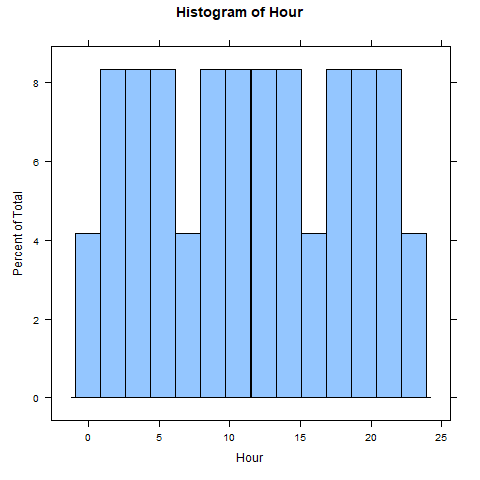

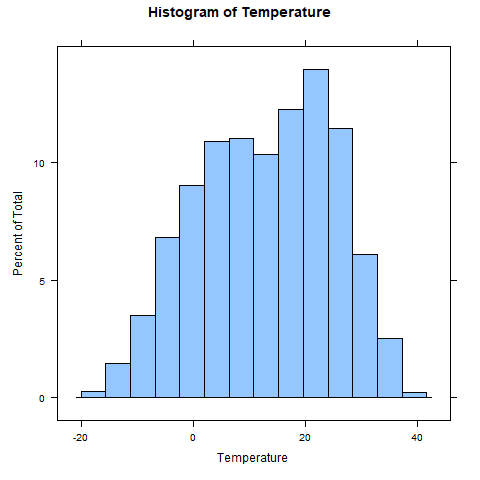

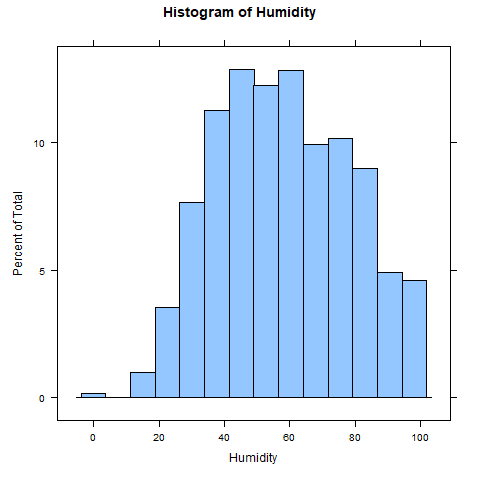

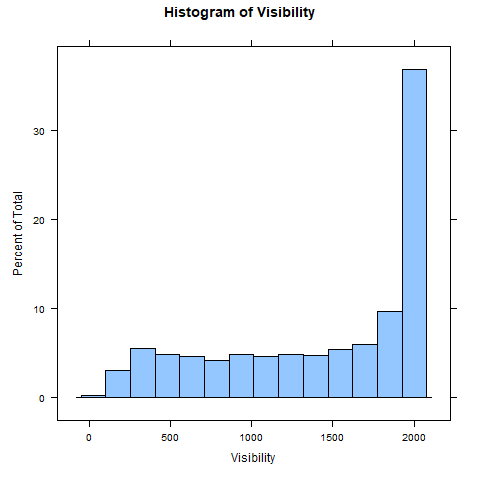

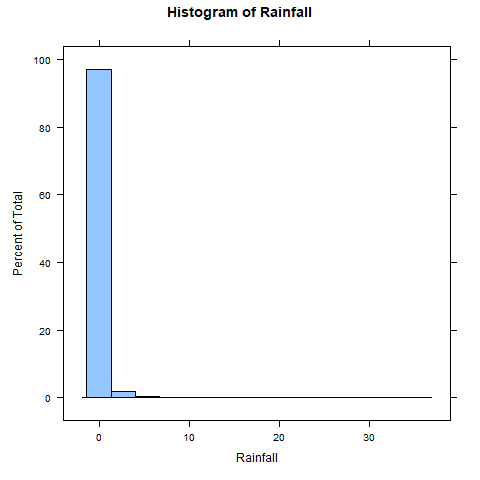

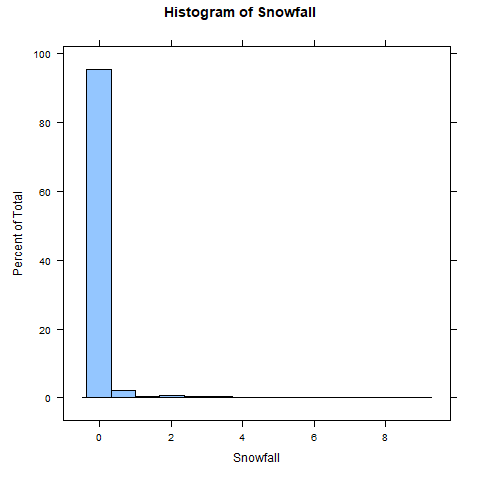

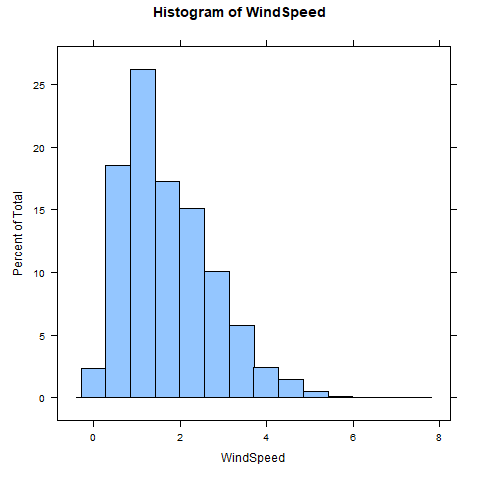

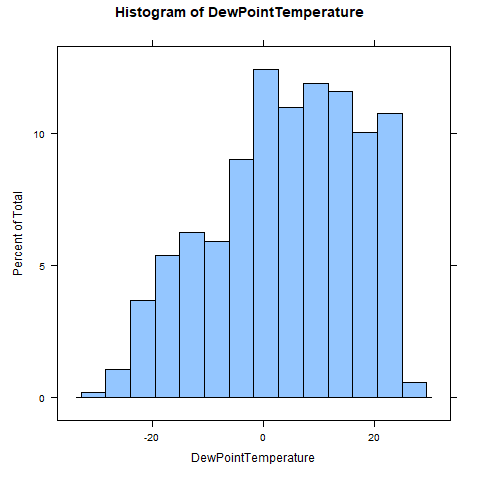

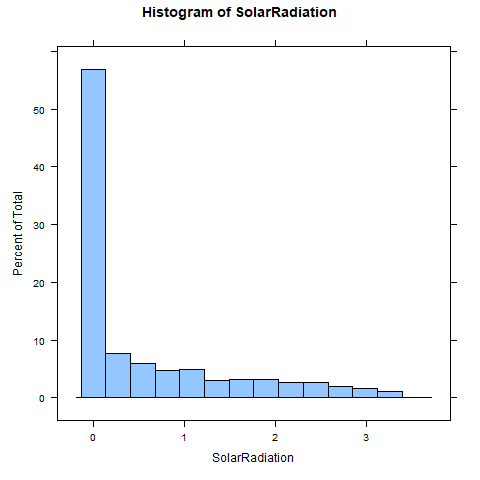

In [50]:
%%R 
print(histogram(dfMedidas$Hour, main = "Histogram of Hour", xlab = "Hour"))
print(histogram(dfMedidas$Temperature, main = "Histogram of Temperature", xlab = "Temperature"))
print(histogram(dfMedidas$Humidity, main = "Histogram of Humidity", xlab = "Humidity"))
print(histogram(dfMedidas$Visibility, main = "Histogram of Visibility", xlab = "Visibility"))
print(histogram(dfMedidas$Rainfall, main = "Histogram of Rainfall", xlab = "Rainfall"))
print(histogram(dfMedidas$Snowfall, main = "Histogram of Snowfall", xlab = "Snowfall"))
print(histogram(dfMedidas$Wind_speed, main = "Histogram of WindSpeed", xlab = "WindSpeed"))
print(histogram(dfMedidas$Dew_point_temperature, main = "Histogram of DewPointTemperature", xlab = "DewPointTemperature"))
print(histogram(dfMedidas$Solar_Radiation, main = "Histogram of SolarRadiation", xlab = "SolarRadiation"))


Podemos ver que la mayoría de variables siguen una distribución normal, y podemos destacar la siguiente información:

* El uso de las bicicletas a lo largo del día sigue un patrón, no una distribución normal.
* Los datos muestran que no hay una gran cantidad de lluvia, nieve o radiación solar.
* La visibilidad es alta.
* Humedad alta.
* Temperatura media alta.

Evaluamos también la presencia de outliers con los diagramas de caja.

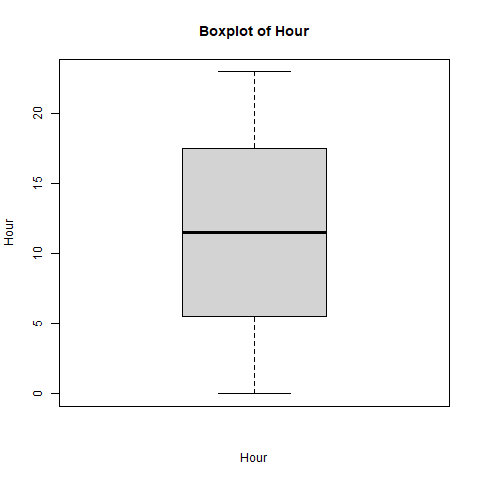

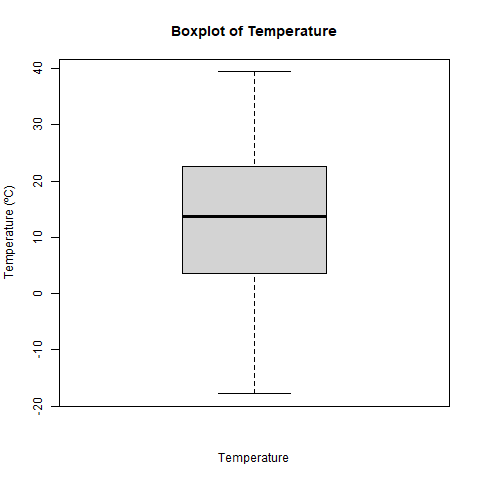

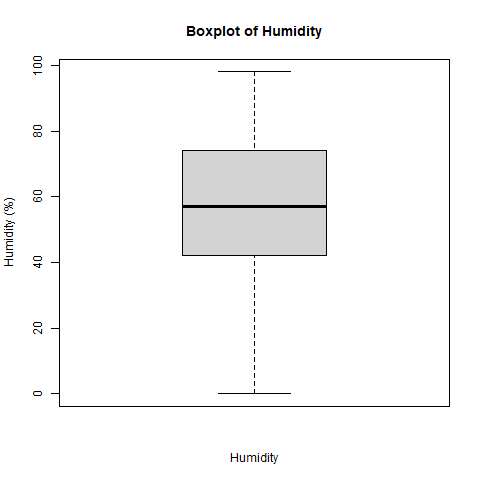

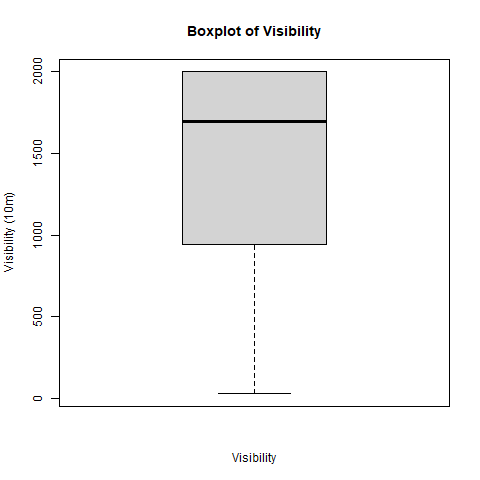

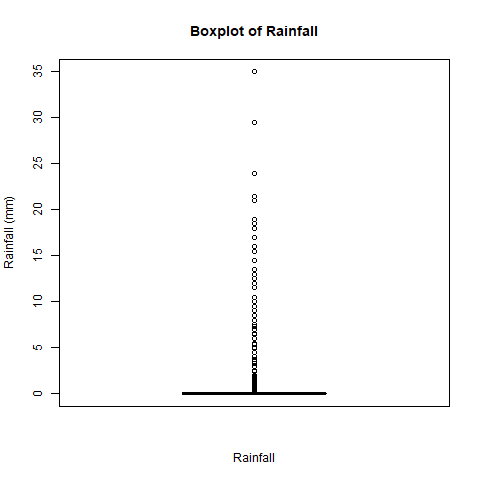

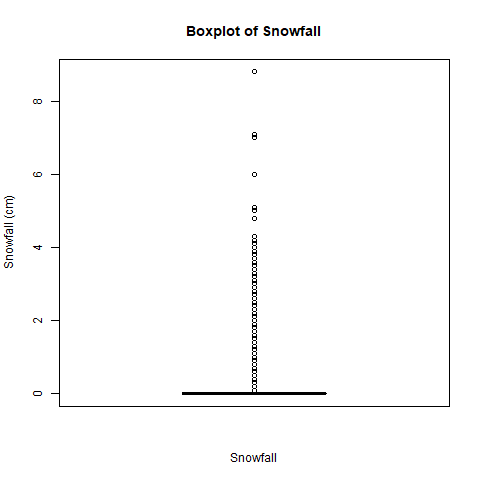

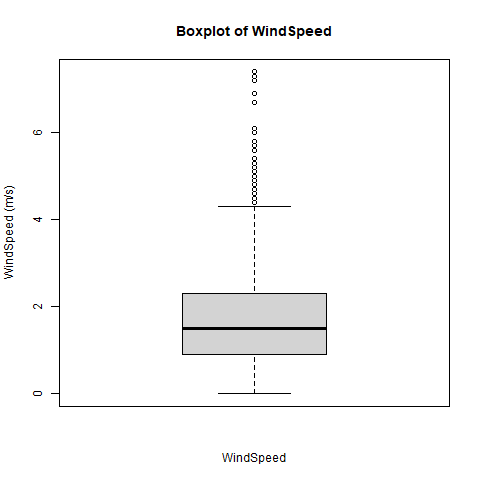

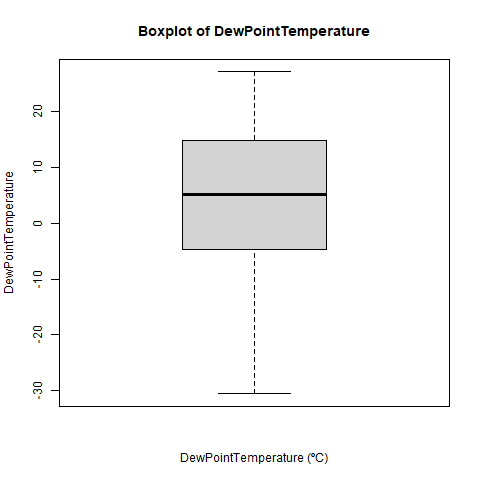

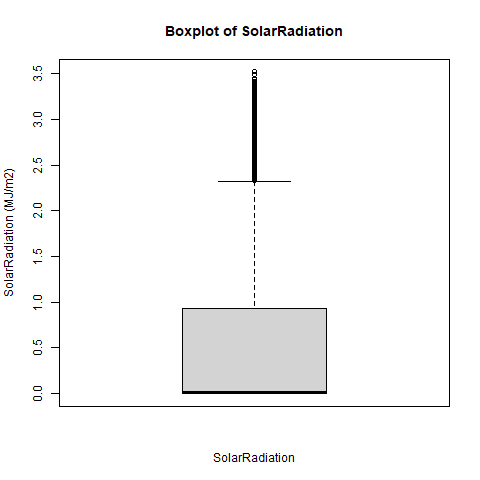

In [23]:
%%R
boxplot(dfMedidas$Hour, main = "Boxplot of Hour", xlab = "Hour", ylab = "Hour")
boxplot(dfMedidas$Temperature, main = "Boxplot of Temperature", xlab = "Temperature", ylab = "Temperature (ºC)")
boxplot(dfMedidas$Humidity, main = "Boxplot of Humidity", xlab = "Humidity", ylab = "Humidity (%)")
boxplot(dfMedidas$Visibility, main = "Boxplot of Visibility", xlab = "Visibility", ylab = "Visibility (10m)")
boxplot(dfMedidas$Rainfall, main = "Boxplot of Rainfall", xlab = "Rainfall", ylab = "Rainfall (mm)")
boxplot(dfMedidas$Snowfall, main = "Boxplot of Snowfall", xlab = "Snowfall", ylab = "Snowfall (cm)")
boxplot(dfMedidas$Wind_speed, main = "Boxplot of WindSpeed", xlab = "WindSpeed", ylab = "WindSpeed (m/s)")
boxplot(dfMedidas$Dew_point_temperature, main = "Boxplot of DewPointTemperature", xlab = "DewPointTemperature (ºC)", ylab = "DewPointTemperature")
boxplot(dfMedidas$Solar_Radiation, main = "Boxplot of SolarRadiation", xlab = "SolarRadiation", ylab = "SolarRadiation (MJ/m2)")

Podemos ver que hay una mayor concentración de Outliers en las variables Rainfall, Snowfall, Windspeed y SolarRadiation, por ello, y para buscar alguna explicación, observaremos el impacto de las estaciones del año en estas variables y en la objetivo.

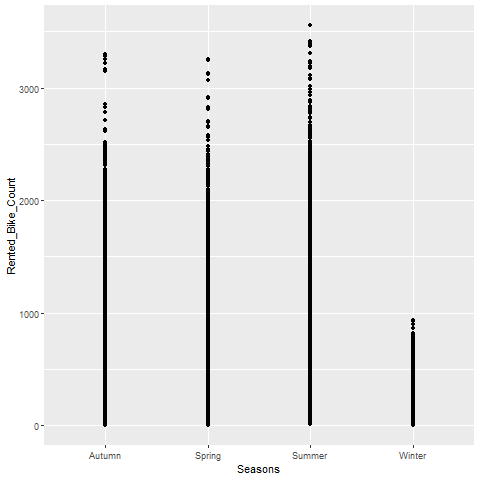

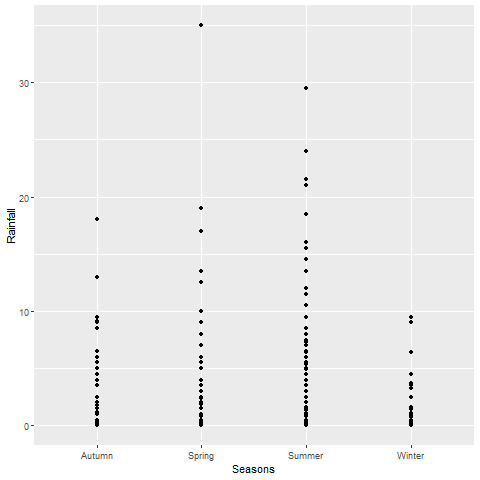

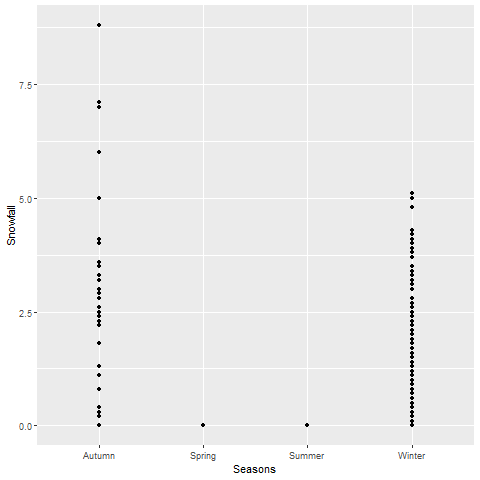

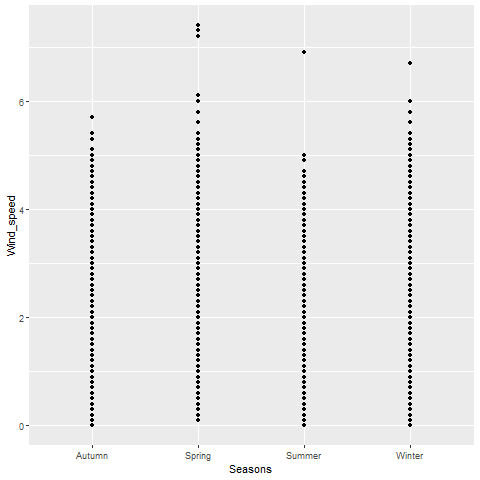

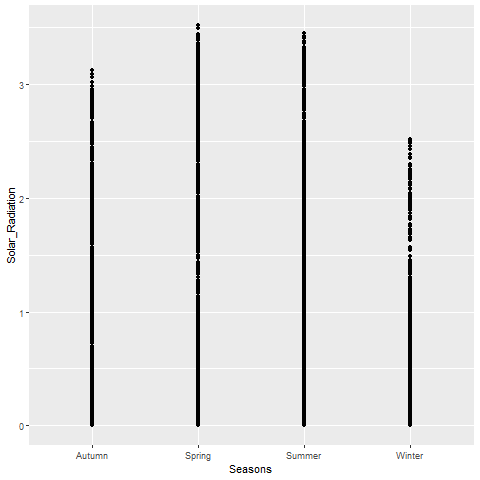

In [51]:
%%R

print(ggplot(dfMedidas, aes(x = Seasons, y = Rented_Bike_Count)) + geom_point())
print(ggplot(dfMedidas, aes(x = Seasons, y = Rainfall)) + geom_point())
print(ggplot(dfMedidas, aes(x = Seasons, y = Snowfall)) + geom_point())
print(ggplot(dfMedidas, aes(x = Seasons, y = Wind_speed)) + geom_point())
print(ggplot(dfMedidas, aes(x = Seasons, y = Solar_Radiation)) + geom_point())

De estas gráficas podemos sacar las siguientes conclusiones:

* Los valores más altos de lluvia se dan en verano y en primavera, dos de las estaciones con mayor uso de las bicicletas, por lo que la presencia de outliers de lluvia es estadísticamente normal.
* Los valores más altos de nieve se dan en otoño y invierno, y aunque en invierno no se usan mucho las bicicletas, en otoño sí, por lo que se da el mismo caso que con la lluvia.
* Los valores más altos de viento se dan en primavera y verano, dándose la misma situación que en los dos casos anteriores.
* Los valores más altos de radiación solar se dan también en primavera y verano, dándose la misma situación que en los dos casos anteriores.

Por todo esto, se puede ver que estos valores que en un principio pueden parecer atípicos, muestran la correlación entre las estaciones y las condiciones meteorológicas.

## Análisis de Correlación:

### Correlación entre variables numéricas

In [13]:
%%R

num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
num_vars <- num_vars[, !names(num_vars) %in% c("Rented_Bike_Count")]
corr_test <- corr.test(num_vars)

# Correlaciones
print(round(corr_test$r, 2))


                       Hour Temperature Humidity Wind_speed Visibility
Hour                 

  1.00        0.12    -0.24       0.29       0.10
Temperature            0.12        1.00     0.16      -0.04       0.03
Humidity              -0.24        0.16     1.00      -0.34      -0.54
Wind_speed             0.29       -0.04    -0.34       1.00       0.17
Visibility             0.10        0.03    -0.54       0.17       1.00
Dew_point_temperature  0.00        0.91     0.54      -0.18      -0.18
Solar_Radiation        0.15        0.35    -0.46       0.33       0.15
Rainfall               0.01        0.05     0.24      -0.02      -0.17
Snowfall              -0.02       -0.22     0.11       0.00      -0.12
                      Dew_point_temperature Solar_Radiation Rainfall Snowfall
Hour                                   0.00            0.15     0.01    -0.02
Temperature                            0.91            0.35     0.05    -0.22
Humidity                               0.54           -0.46     0.24     0.11
Wind_speed                            -0.18            0.33    -0.02  

Y de una forma más visual:

In addition: Warning message:
The `...` argument of `ggpais()` is deprecated as of GGally 2.3.0.
This warning is displayed once every 8 hours.
Call `lifecycle::last_lifecycle_warnings()` to see where this warning was
generated. 


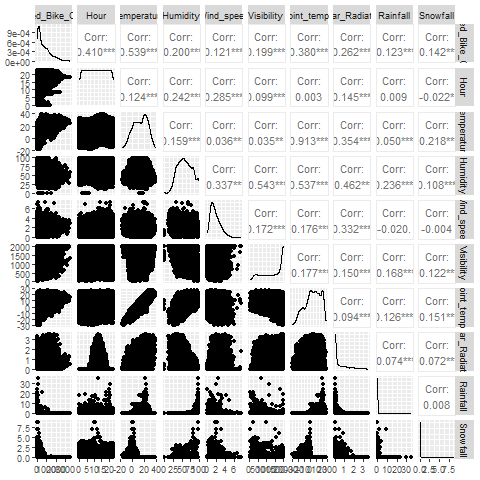

In [14]:
%%R
num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
ggpairs(num_vars, size = 3)

R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xe1 in position 17: invalid continuation byte <traceback object at 0x00000258A7D92400>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xe1 in position 17: invalid continuation byte <traceback object at 0x00000258A7D93B00>
R callback write-console: <class 'UnicodeDecodeError'> 'utf-8' codec can't decode byte 0xe1 in position 17: invalid continuation byte <traceback object at 0x00000258A75EFC80>


In addition: Warning messages:
1: In text.default(pos.xlabel[, 1], pos.xlabel[, 2], newcolnames, srt = tl.srt,  :
 2: In text.default(pos.ylabel[, 1], pos.ylabel[, 2], newrownames, col = tl.col,  :
 3: In title(title, ...) :

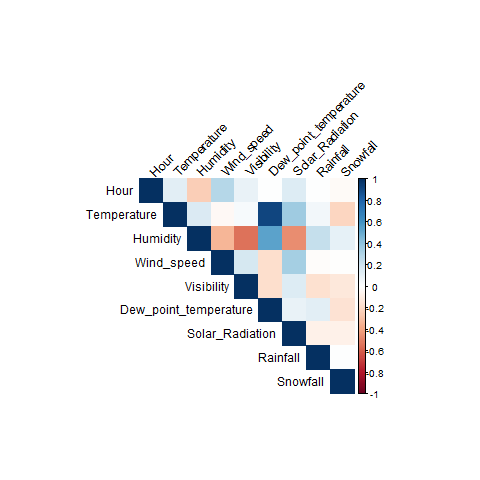

In [15]:
%%R
num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
cor_matrix <- cor(num_vars, use = "complete.obs")

corrplot(corr_test$r,
        type = "upper", 
        method = "color", 
        tl.col = "black", 
        tl.srt = 45,
        size = 10)

Podemos ver que las variables más relacionadas son la temperatura con la temperatura del punto de rocío (91%), humedad con visibilidad (-54%) y humedad con la temperatura del punto de rocío (54%). 

Estas relaciones tienen sentido, ya que, la temperatura del punto de rocío depende directamente con la temperatura ambiental, por otro lado, una mayor humedad puede derivar en una menor visibilidad por factores como la condensación (niebla, bruma, bochorno, ...), por último, la temperatura del punto de rocío se relaciona tanto con la humedad debido a que la humedad mide el vapor de agua ambiental, mientras que el punto de rocío mide la temperatura a partir de la cual esa humedad ambiental alcance el 100%.

Estas relaciones significativas habrá que tenerlas en cuenta en el futuro, ya que, la informaciñon que aportan cada una de las variables de cada par puede llegar a ser redundante.

### Correlación con la variable objetivo:

Evaluamos la correlación de las variables numéricas con la variable objetivo

In [16]:
%%R
library(ggplot2)

target <- "Rented_Bike_Count"

num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
correlations <- cor(num_vars, use = "complete.obs", method = "pearson")[, target]

cor_df <- data.frame(
  Variable = names(correlations),
  Correlation = correlations
)
cor_df <- cor_df[cor_df$Variable != target, ]
cor_df <- cor_df[order(-abs(cor_df$Correlation)), ]

print(cor_df)


                                   Variable Correlation
Temperature                     Temperature   0.5385582
Hour                                   Hour   0.4102573
Dew_point_temperature Dew_point_temperature   0.3797881
Solar_Radiation             Solar_Radiation   0.2618370
Humidity                           Humidity  -0.1997802
Visibility                       Visibility   0.1992803
Snowfall                           Snowfall  -0.1418036
Rainfall                           Rainfall  -0.1230740
Wind_speed                       Wind_speed   0.1211084


Como podemos ver la variable más relacionada con la objetivo es temperatura (54% de correlación), es decir, cuanto mayor es la temperatura mayor es el uso de las biciletas, esto responde al comportamiento promedio del usuario de bicicletas.
Por otro lado, el resto de valores no son significativos.